# 02 — Target Selection

**Goal** – Decide between `log1p(play_count)` at day 7, 14, or 30, and
between an *absolute* and *relative* (creator-centred) target formulation.
Five questions are answered in sequence.

**Input** – The three raw tables + `config/default.yaml`.

**Conclusion** –
**Day 14** is the right measurement point: 100 % exact coverage (day 7 = 98.4 %;
day 30 = 35.3 %). Using day 29 as the final reference (92.4 % coverage, n = 193 665):
by day 14, videos hold a median **95.7 %** of their day-29 play_count (80.2 % are
already ≥ 90 %; Spearman ρ = 0.996 with day-29).
1 240 videos (0.59 %) have a monotonicity violation; when present the median drop
is 96.2 % of peak — a data-collection reset artefact, excluded from all targets.
**Relative target is strongly preferred**: 73.2 % of the variance in the absolute
`log1p(play_count_day14)` is explained by `author_id` alone (test R² = 0.732); the
relative target reduces this to 4.4 %, isolating content-driven variance.
The "author-only" baseline has RMSE = 0.984 on the relative target
(≈ ×2.7 — the bar any model must beat). Engagement rate has a weaker creator effect
(test R² = 0.493, creator explains 49.3 %).
`follower_count` at publish time (as-of backward join, 100 % coverage) has
Spearman ρ = 0.645 with the absolute target — a powerful feature, not a target
component. Per-creator Spearman correlations show cross-creator heterogeneity in
feature effects for all features (std_real/std_null > 1): highest for `duration`
(1.58) and `word_count` (1.57); lowest for emotions ≈ 1.2–1.3. This motivates
per-creator models.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


In [3]:
from creator_analytics.config import load_config
from creator_analytics.data import filter_creators, load_raw_table, train_test_split_by_creator
from creator_analytics.features import follower_asof_join
from creator_analytics.targets import build_target

cfg    = load_config("config/default.yaml")
RAW    = cfg["paths"]["raw_dir"]
FIGS   = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")
print(f"videos {len(videos):,}  creator_daily {len(creator_daily):,}  engagement {len(engagement):,}")


videos 209,543  creator_daily 278,433  engagement 6,068,955


## 1. Coverage by `days_since_post`

In [4]:
total = videos["video_id"].nunique()
rows = []
for day in [0, 7, 14, 21, 28, 30]:
    exact = engagement[engagement["days_since_post"] == day]["video_id"].nunique()
    geq   = engagement[engagement["days_since_post"] >= day]["video_id"].nunique()
    rows.append({"day": day,
                 "exact_n": exact, "exact_%": round(exact / total * 100, 1),
                 "≥day_n": geq,    "≥day_%":  round(geq   / total * 100, 1)})

display(pd.DataFrame(rows).set_index("day"))

# tracking window per video
max_day = engagement.groupby("video_id")["days_since_post"].max()
n_days  = engagement.groupby("video_id")["days_since_post"].nunique()
print(f"\nDistinct days tracked per video: "
      f"median={n_days.median():.0f}  p5={n_days.quantile(0.05):.0f}  p95={n_days.quantile(0.95):.0f}")


,exact_n,exact_%,≥day_n,≥day_%
day,,,,
0,157065,75.0,209543,100.0
7,206216,98.4,209543,100.0
14,209543,100.0,209543,100.0
21,195654,93.4,209452,100.0
28,193465,92.3,198733,94.8
30,73940,35.3,73940,35.3



Distinct days tracked per video: median=30  p5=22  p95=31


> **Key observation**: day 14 is the *only* day with 100 % exact coverage.
> Day 30 is 35.3 %; day 7 is 98.4 %.  Use the table above to compare.


days_since_post distribution across all rows:
  min=0  p25=7  median=14  p75=22  max=30


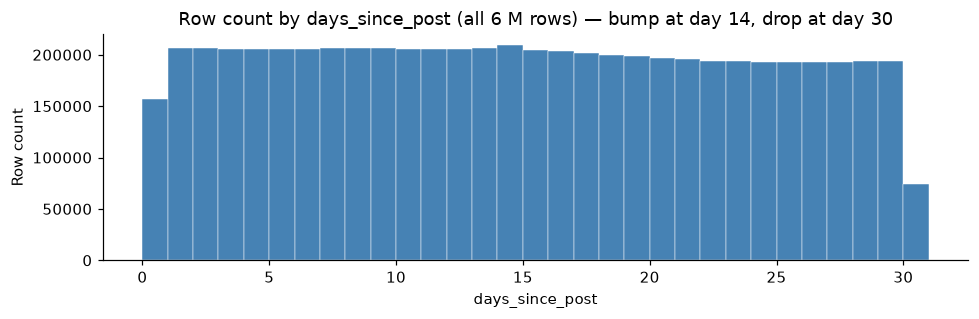

In [5]:
dsp = engagement["days_since_post"]
print("days_since_post distribution across all rows:")
print(f"  min={dsp.min()}  p25={dsp.quantile(0.25):.0f}  "
      f"median={dsp.median():.0f}  p75={dsp.quantile(0.75):.0f}  max={dsp.max()}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(dsp.values, bins=range(0, 32), color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_xlabel("days_since_post")
ax.set_ylabel("Row count")
ax.set_title("Row count by days_since_post (all 6 M rows) — bump at day 14, drop at day 30")
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
fig.tight_layout()
fig.savefig(FIGS / "fig1_coverage_dsp.png", dpi=120)
plt.show()


## 2. Monotonicity of `play_count`

In [6]:
eng_s = engagement.sort_values(["video_id", "days_since_post"]).copy()
eng_s["play_diff"] = eng_s.groupby("video_id")["play_count"].diff()

viols = eng_s[eng_s["play_diff"] < 0]
n_viol = viols["video_id"].nunique()
print(f"Videos with ≥1 decrease in play_count : {n_viol:,}  "
      f"({n_viol / len(videos) * 100:.2f}%)")
print(f"Total violation rows                    : {len(viols):,}")

if n_viol:
    max_drop = viols.groupby("video_id")["play_diff"].min().abs()
    peak     = engagement.groupby("video_id")["play_count"].max()
    sev      = (max_drop / peak * 100).dropna()
    print(f"Max drop as % of peak — median={sev.median():.1f}%  p95={sev.quantile(0.95):.1f}%")
    print("→ Violations are severe but rare; likely a data-collection reset artefact.")


Videos with ≥1 decrease in play_count : 1,240  (0.59%)
Total violation rows                    : 1,241
Max drop as % of peak — median=96.2%  p95=100.0%
→ Violations are severe but rare; likely a data-collection reset artefact.


## 3. View accumulation: fraction of day-29 play_count

Videos with day-29 record (reference): 193,665  (92.4%)

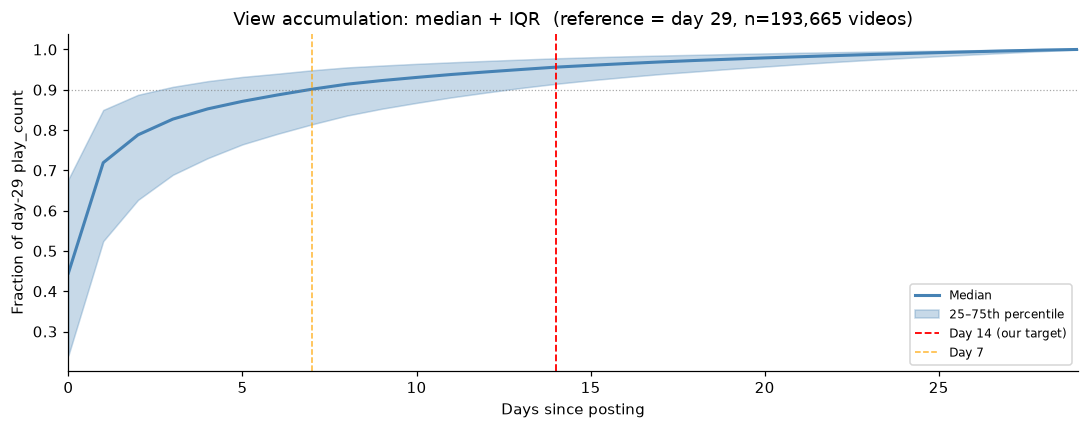

In [7]:
def _exact_plays(day: int) -> pd.Series:
    return engagement[engagement["days_since_post"] == day].set_index("video_id")["play_count"]

pc7, pc14, pc29 = _exact_plays(7), _exact_plays(14), _exact_plays(29)
n_ref = len(pc29)
print(f"Videos with day-29 record (reference): {n_ref:,}  ({n_ref/len(videos)*100:.1f}%)")

rng_acc = np.random.default_rng(cfg["seed"])
sample_ids = rng_acc.choice(pc29.index.to_numpy(), size=min(20_000, n_ref), replace=False)

curve = (engagement[engagement["video_id"].isin(sample_ids)]
         .pivot_table(index="video_id", columns="days_since_post",
                      values="play_count", aggfunc="first"))
curve_frac = curve.div(curve[29].replace(0, np.nan), axis=0)

days_plot = sorted([d for d in range(0, 30) if d in curve_frac.columns])
med_vals  = curve_frac[days_plot].median()
p25_vals  = curve_frac[days_plot].quantile(0.25)
p75_vals  = curve_frac[days_plot].quantile(0.75)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(days_plot, med_vals, color="steelblue", linewidth=2, label="Median")
ax.fill_between(days_plot, p25_vals, p75_vals, alpha=0.3, color="steelblue",
                label="25–75th percentile")
ax.axvline(14, color="red", linestyle="--", linewidth=1.2, label="Day 14 (our target)")
ax.axvline(7,  color="orange", linestyle="--", linewidth=1.0, alpha=0.8, label="Day 7")
ax.axhline(0.9, color="gray", linestyle=":", linewidth=0.8, alpha=0.7)
ax.set_xlabel("Days since posting"); ax.set_ylabel("Fraction of day-29 play_count")
ax.set_title(f"View accumulation: median + IQR  (reference = day 29, n={n_ref:,} videos)")
ax.legend(fontsize=8); ax.set_xlim(0, 29)
fig.tight_layout()
fig.savefig(FIGS / "fig2_accumulation_curve.png", dpi=120)
plt.show()


In [8]:
rows_cmp = []
for label, pcN in [("day 7", pc7), ("day 14", pc14)]:
    common = pcN.index.intersection(pc29.index)
    ratio  = (pcN.loc[common] / pc29.loc[common].replace(0, np.nan)).dropna()
    spe    = pcN.loc[common].corr(pc29.loc[common], method="spearman")
    q      = ratio.quantile([0.05, 0.50])
    rows_cmp.append({
        "day": label,
        "n": len(common),
        "median": round(q[0.50], 3),
        "p5": round(q[0.05], 3),
        "≥0.9": f"{(ratio >= 0.9).mean():.1%}",
        "Spearman w/ day-29": round(spe, 3),
    })

display(pd.DataFrame(rows_cmp).set_index("day"))
print(f"\n→ By day 14, a typical video has {rows_cmp[1]['median']:.1%} of its day-29 play_count.")


,n,median,p5,≥0.9,Spearman w/ day-29
day,,,,,
day 7,190377,0.903,0.574,51.4%,0.990
day 14,193665,0.957,0.776,80.2%,0.996



→ By day 14, a typical video has 95.7% of its day-29 play_count.


## 4. Absolute vs relative target

In [9]:
min_vids = cfg["data"]["min_videos_per_creator"]
seed     = cfg["seed"]

vids_f   = filter_creators(videos, "author_id", min_videos=min_vids)
train_df, test_df = train_test_split_by_creator(vids_f, "author_id", test_size=0.2, seed=seed)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])
print(f"Filtered (≥{min_vids} videos): {len(vids_f):,} videos  {vids_f['author_id'].nunique():,} creators")
print(f"Train: {len(train_df):,}  |  Test: {len(test_df):,}")


Filtered (≥30 videos): 201,832 videos  1,439 creators
Train: 161,465  |  Test: 40,367


In [10]:
abs_t = build_target(engagement, vids_f, day=14, mode="absolute")
rel_t = build_target(engagement, vids_f, day=14, mode="relative",
                     train_video_ids=train_ids)


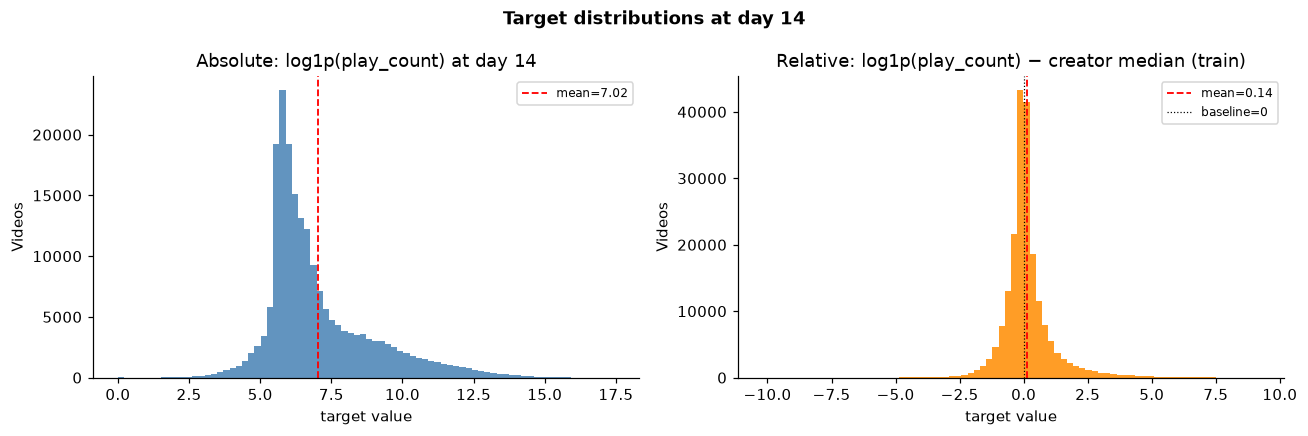

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, t, color, title in [
    (axes[0], abs_t, "steelblue",
     "Absolute: log1p(play_count) at day 14"),
    (axes[1], rel_t, "darkorange",
     "Relative: log1p(play_count) − creator median (train)"),
]:
    ax.hist(t["target"], bins=80, color=color, edgecolor="none", alpha=0.85)
    ax.axvline(t["target"].mean(), color="red", linewidth=1.2, linestyle="--",
               label=f"mean={t['target'].mean():.2f}")
    if color == "darkorange":
        ax.axvline(0, color="black", linewidth=0.8, linestyle=":", label="baseline=0")
    ax.set_xlabel("target value"); ax.set_ylabel("Videos")
    ax.set_title(title); ax.legend(fontsize=8)

fig.suptitle("Target distributions at day 14", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "fig3_target_distributions.png", dpi=120)
plt.show()


In [12]:
def _metrics(y, pred):
    """R² і RMSE для одного набору (y — справжні значення, pred — прогноз)."""
    resid = y - pred
    ss_res = (resid ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return {"R2": float(1 - ss_res / ss_tot),
            "RMSE": float(np.sqrt((resid ** 2).mean()))}


def _author_baseline(target_df: pd.DataFrame) -> dict:
    """Модель 'прогноз = середнє target автора на train': метрики на train і test."""
    td = target_df.merge(vids_f[["video_id", "author_id"]], on="video_id", how="inner")
    tr = td[td["video_id"].isin(train_ids)]
    te = td[td["video_id"].isin(test_ids)]

    author_means = tr.groupby("author_id")["target"].mean()
    tr_pred = tr["author_id"].map(author_means)
    te_pred = te["author_id"].map(author_means).fillna(tr["target"].mean())

    return {"train": _metrics(tr["target"], tr_pred),
        "test":  _metrics(te["target"], te_pred),
        "train_std": float(tr["target"].std()),
        "test_std":  float(te["target"].std())}

res = {"Absolute": _author_baseline(abs_t), "Relative": _author_baseline(rel_t)}

print("Модель 'лише автор' (прогноз = середнє target автора на train)\n")
print(f"{'target':<10}|{'R² train':>9} |{'R² test':>8} |{'RMSE train':>11} |{'RMSE test':>10} "
      f"|{'std train':>10} |{'std test':>9}")
for name, r in res.items():
    print(f"{name:<10}|{r['train']['R2']:>9.3f} |{r['test']['R2']:>8.3f} |"
        f"{r['train']['RMSE']:>11.3f} |{r['test']['RMSE']:>10.3f} |"
        f"{r['train_std']:>10.3f} |{r['test_std']:>9.3f}")

a, rl = res["Absolute"]["test"], res["Relative"]["test"]
print(f"\n→ {a['R2']:.1%} дисперсії absolute target пояснюється лише автором.")
print(f"→ Для relative target — {max(rl['R2'], 0):.1%}.")
print(f"→ Типова помилка 'лише автор' на relative target: RMSE = {rl['RMSE']:.3f} "
      f"(≈ ×{np.exp(rl['RMSE']):.1f} у той чи інший бік) — планка, яку має побити модель.")


Модель 'лише автор' (прогноз = середнє target автора на train)

target    | R² train | R² test | RMSE train | RMSE test | std train | std test
Absolute  |    0.739 |   0.732 |      0.968 |     0.984 |     1.894 |    1.900
Relative  |    0.046 |   0.044 |      0.968 |     0.984 |     0.990 |    1.006

→ 73.2% дисперсії absolute target пояснюється лише автором.
→ Для relative target — 4.4%.
→ Типова помилка 'лише автор' на relative target: RMSE = 0.984 (≈ ×2.7 у той чи інший бік) — планка, яку має побити модель.


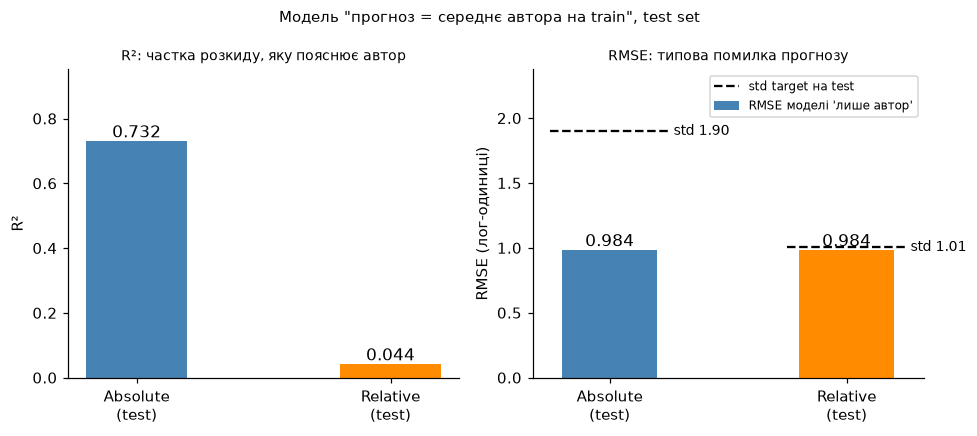

In [13]:
names  = ["Absolute", "Relative"]
xlabs  = ["Absolute\n(test)", "Relative\n(test)"]
colors = ["steelblue", "darkorange"]
r2     = [max(res[n]["test"]["R2"], 0) for n in names]
rmse   = [res[n]["test"]["RMSE"] for n in names]
std    = [res[n]["test_std"] for n in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

bars = ax1.bar(xlabs, r2, color=colors, width=0.4)
for bar, h in zip(bars, r2):
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", fontsize=11)
ax1.set_ylim(0, max(r2) * 1.3)
ax1.set_ylabel("R²")
ax1.set_title("R²: частка розкиду, яку пояснює автор", fontsize=9)

bars = ax2.bar(xlabs, rmse, color=colors, width=0.4, label="RMSE моделі 'лише автор'")
for bar, h, s in zip(bars, rmse, std):
    x = bar.get_x() + bar.get_width() / 2
    ax2.text(x, h + 0.03, f"{h:.3f}", ha="center", fontsize=11)
    ax2.hlines(s, bar.get_x() - 0.05, bar.get_x() + bar.get_width() + 0.05,
               colors="black", linestyles="--")
    ax2.text(bar.get_x() + bar.get_width() + 0.07, s, f"std {s:.2f}", va="center", fontsize=9)
ax2.plot([], [], "k--", label="std target на test")
ax2.set_ylim(0, max(std + rmse) * 1.25)
ax2.set_ylabel("RMSE (лог-одиниці)")
ax2.set_title("RMSE: типова помилка прогнозу", fontsize=9)
ax2.legend(fontsize=8, loc="upper right")

fig.suptitle('Модель "прогноз = середнє автора на train", test set', fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "fig4_author_r2_rmse.png", dpi=120)
plt.show()


In [14]:
eng14_er = (engagement[engagement["days_since_post"] == 14]
            [["video_id", "play_count", "like_count", "comment_count", "share_count"]])
eng14_er = eng14_er[eng14_er["play_count"] > 0].copy()
eng14_er["engagement_rate"] = (
    (eng14_er["like_count"] + eng14_er["comment_count"] + eng14_er["share_count"])
    / eng14_er["play_count"])

er_t = (vids_f[["video_id"]]
        .merge(eng14_er[["video_id", "engagement_rate"]], on="video_id")
        .rename(columns={"engagement_rate": "target"}))
er_res = _author_baseline(er_t)
print("Engagement rate = (likes+comments+shares) / play_count at day 14")
print(f"Creator explains {er_res['test']['R2']:.1%} of engagement_rate variance "
      f"(vs {res['Absolute']['test']['R2']:.1%} for log-views).")
print(f"R² train={er_res['train']['R2']:.3f}  test={er_res['test']['R2']:.3f}")


Engagement rate = (likes+comments+shares) / play_count at day 14
Creator explains 49.3% of engagement_rate variance (vs 73.2% for log-views).
R² train=0.510  test=0.493


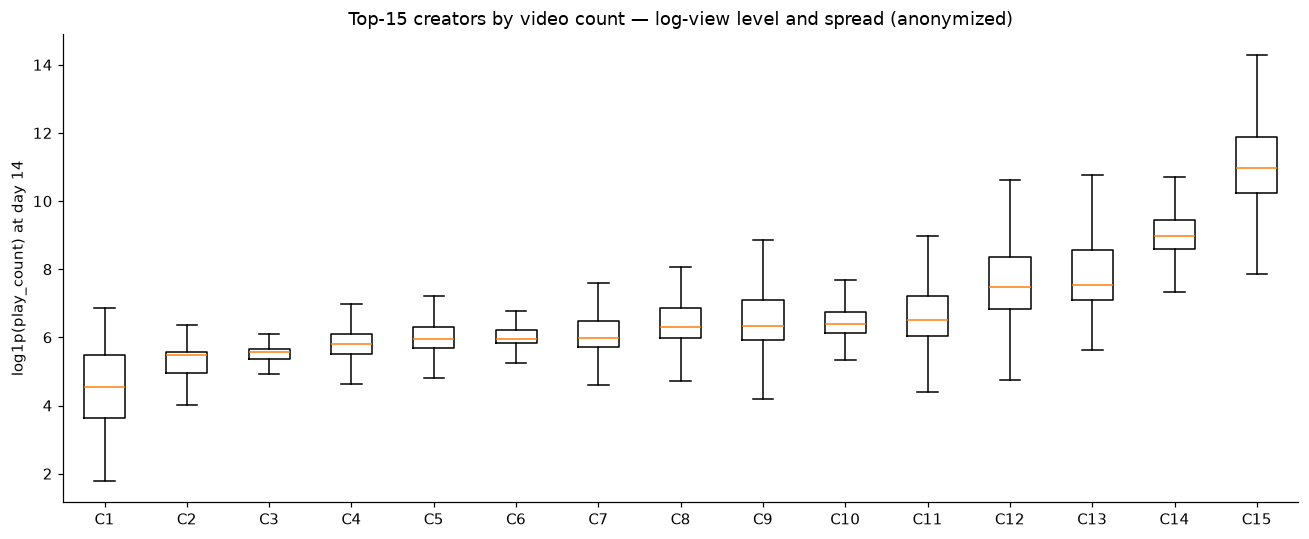

In [15]:
abs_with_auth = abs_t.merge(vids_f[["video_id", "author_id"]], on="video_id")
top15 = vids_f["author_id"].value_counts().head(15).index
d15   = abs_with_auth[abs_with_auth["author_id"].isin(top15)]
order = d15.groupby("author_id")["target"].median().sort_values().index

labels15 = [f"C{i+1}" for i in range(len(order))]
groups15  = [d15.loc[d15["author_id"] == a, "target"].values for a in order]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(groups15, tick_labels=labels15, showfliers=False)
ax.set_ylabel("log1p(play_count) at day 14")
ax.set_title("Top-15 creators by video count — log-view level and spread (anonymized)")
fig.tight_layout()
fig.savefig(FIGS / "fig4b_top15_creators.png", dpi=120)
plt.show()


## 5. Follower count at publish time (as-of join)

In [16]:
videos_with_fc = follower_asof_join(videos, creator_daily)
cov = videos_with_fc["follower_count_at_publish"].notna().mean()
print(f"Coverage: {cov*100:.1f}%  ({videos_with_fc['follower_count_at_publish'].notna().sum():,} videos)")

joined = (abs_t
          .merge(videos_with_fc[["video_id", "follower_count_at_publish"]], on="video_id")
          .dropna(subset=["follower_count_at_publish"]))
joined["log_fc"] = np.log1p(joined["follower_count_at_publish"].clip(0))
pearson  = joined["log_fc"].corr(joined["target"])
spearman = joined["log_fc"].corr(joined["target"], method="spearman")
print(f"Pearson r  = {pearson:.3f}  (n={len(joined):,})")
print(f"Spearman ρ = {spearman:.3f}")


Coverage: 100.0%  (209,543 videos)
Pearson r  = 0.682  (n=201,832)
Spearman ρ = 0.645


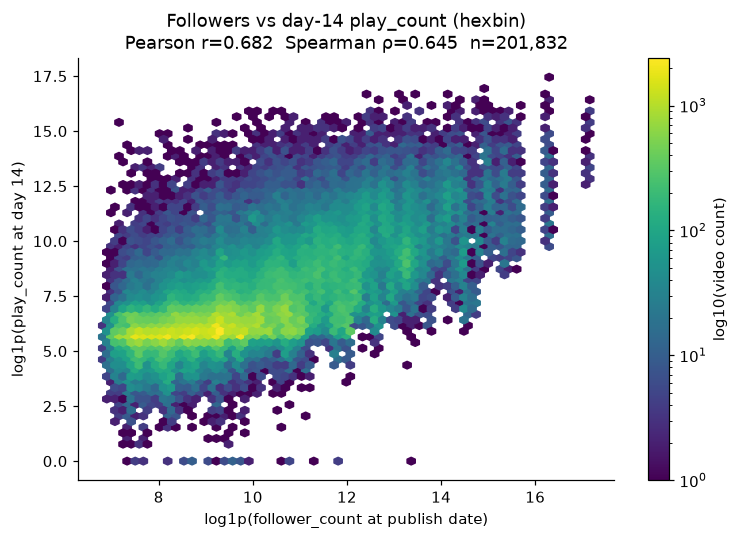

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(joined["log_fc"], joined["target"], gridsize=60, bins="log", cmap="viridis")
ax.set_xlabel("log1p(follower_count at publish date)")
ax.set_ylabel("log1p(play_count at day 14)")
ax.set_title(f"Followers vs day-14 play_count (hexbin)\n"
             f"Pearson r={pearson:.3f}  Spearman ρ={spearman:.3f}  n={len(joined):,}")
fig.colorbar(hb, label="log10(video count)")
fig.tight_layout()
fig.savefig(FIGS / "fig5_follower_vs_target.png", dpi=120)
plt.show()


## 6. Per-creator correlations: do feature effects vary between creators?

In [18]:
FEATS_PC = ["duration", "word_count", "emoji_count", "question_count",
            "hashtag_count", "speaking_rate", "joy", "sadness",
            "disgust", "surprise", "anger", "fear"]

dfc_pc = (vids_f[["video_id", "author_id"]]
          .merge(abs_t[["video_id", "target"]], on="video_id")
          .merge(videos[["video_id"] + FEATS_PC + ["transcript", "sticker_text"]], on="video_id"))
dfc_pc["has_transcript"]   = dfc_pc["transcript"].notna().astype(float)
dfc_pc["has_sticker_text"] = dfc_pc["sticker_text"].notna().astype(float)

FEATS_ALL = FEATS_PC + ["has_transcript", "has_sticker_text"]

rng_pc = np.random.default_rng(cfg["seed"])
dfc_pc["target_shuf"] = dfc_pc.groupby("author_id")["target"].transform(
    lambda s: rng_pc.permutation(s.to_numpy()))

def _creator_corr(df, feat, tgt):
    return df.groupby("author_id")[[feat, tgt]].apply(
        lambda g: g[feat].corr(g[tgt], method="spearman")).dropna()

pc_rows = []
for f in FEATS_ALL:
    r_real = _creator_corr(dfc_pc, f, "target")
    r_null = _creator_corr(dfc_pc, f, "target_shuf")
    r_glob = dfc_pc[f].corr(dfc_pc["target"], method="spearman")
    pc_rows.append({
        "feature": f,
        "global_ρ": round(r_glob, 3),
        "median_per-creator": round(r_real.median(), 3),
        "std_real": round(r_real.std(), 3),
        "std_null": round(r_null.std(), 3),
        "std_real/std_null": round(r_real.std() / r_null.std(), 2),
        "frac_opposite_sign": round((np.sign(r_real) != np.sign(r_glob)).mean(), 3),
    })

pc_df = (pd.DataFrame(pc_rows).set_index("feature")
         .sort_values("std_real/std_null", ascending=False))
display(pc_df)


,global_ρ,median_per-creator,std_real,std_null,std_real/std_null,frac_opposite_sign
feature,,,,,,
duration,0.116,-0.023,0.178,0.113,1.58,0.550
word_count,0.478,0.151,0.231,0.147,1.57,0.236
has_transcript,0.128,0.027,0.162,0.114,1.42,0.449
has_sticker_text,0.107,0.077,0.167,0.118,1.41,0.317
question_count,0.311,0.092,0.185,0.135,1.38,0.297
hashtag_count,0.070,0.054,0.204,0.151,1.35,0.390
joy,-0.014,-0.028,0.152,0.113,1.35,0.420
disgust,-0.046,0.029,0.143,0.109,1.31,0.580
speaking_rate,0.170,0.030,0.192,0.148,1.30,0.439


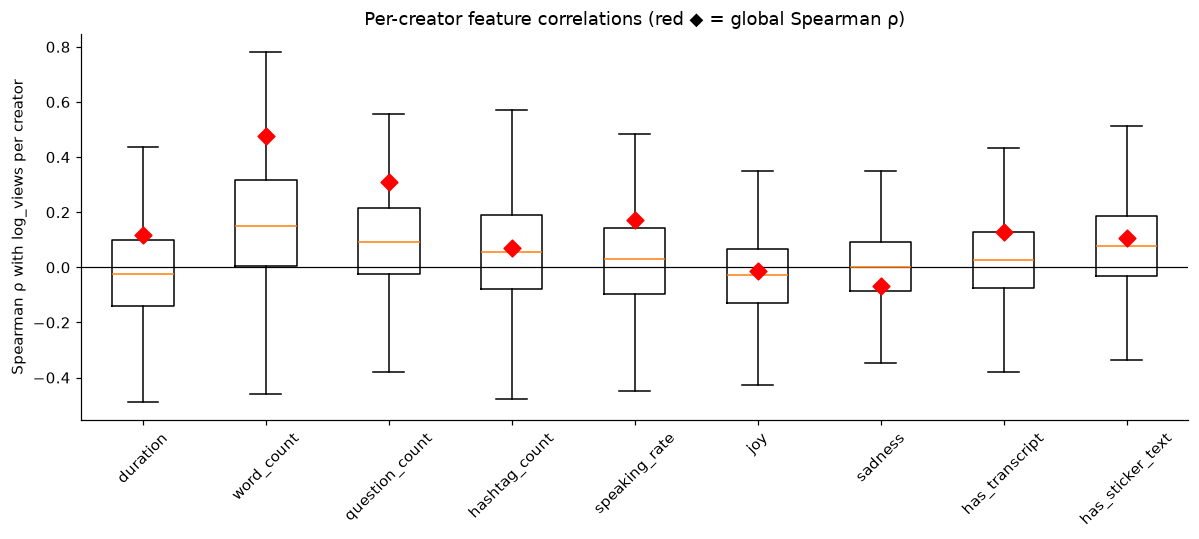

In [19]:
FEATS_PLOT_PC = ["duration", "word_count", "question_count", "hashtag_count",
                 "speaking_rate", "joy", "sadness", "has_transcript", "has_sticker_text"]

real_dists = {f: _creator_corr(dfc_pc, f, "target").values for f in FEATS_PLOT_PC}

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([real_dists[f] for f in FEATS_PLOT_PC],
           tick_labels=FEATS_PLOT_PC, showfliers=False)
for i, f in enumerate(FEATS_PLOT_PC, 1):
    if f in pc_df.index:
        ax.scatter(i, pc_df.loc[f, "global_ρ"], color="red", zorder=5, s=60, marker="D")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Spearman ρ with log_views per creator")
ax.set_title("Per-creator feature correlations (red ◆ = global Spearman ρ)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGS / "fig6_per_creator_correlations.png", dpi=120)
plt.show()
